### Demographics and Building Damage: Who Gets Hit Hardest?



**Target leakage** occurs when a machine learning model uses information during training that would not be available at the time of making an actual prediction. This gives the model an unfair advantage and can make its performance appear better than it really is.

**Why it's called "the silent killer"**

leaky models look excellent during development (training accuracy 99%!) but fail catastrophically in production (test accuracy 65%). There is no error message, no warning. The model trains successfully, evaluates well, and then fails when it matters most.

**The governing rule**: every feature must represent information that exists BEFORE the event we are trying to predict. For earthquake damage prediction: if the feature was measured or generated after the earthquake, it cannot be used.

When the encoder fits on the full dataset (including test), it uses test-set statistics to inform the encoding — a subtle form of information leakage from test to train.

⚠️ This is why we use Pipeline. A sklearn.Pipeline automatically applies fit_transform only during fit(), and only transform during predict(). It enforces the correct train-only fitting discipline without manual code management.

## High cardinality
**High cardinality** in machine learning refers to a categorical feature (column) that contains a large number of unique values.

**Problems :**

- Rare categories get very few training examples → model can't learn reliable patterns
- Many extra columns → overfitting risk, slower training
- Test data may have categories unseen during training → encoder errors

**Solution**: Keep top-N, group the rest:

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot  as plt
import duckdb
from sklearn.model_selection import train_test_split
from category_encoders import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score


In [49]:
conn=duckdb.connect('../data/nepal.sqlite')
df_demo=conn.execute(
    """ 
    SELECT *
    FROM household_demographics
    LIMIT 5
    """
).df()

df_demo

,household_id,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household
0,101,Male,31.0,Rai,Illiterate,Rs. 10 thousand,3.0,0.0
1,201,Female,62.0,Rai,Illiterate,Rs. 10 thousand,6.0,0.0
2,301,Male,51.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,13.0,0.0
3,401,Male,48.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,5.0,0.0
4,501,Male,70.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,8.0,0.0


In [50]:
count_households=conn.execute(
    """ 
    SELECT COUNT(*) as total_houshold
    FROM household_demographics
    """
).df()

count_households["total_houshold"]

0    249932
Name: total_houshold, dtype: int64

In [51]:
district_id=4

df_join=conn.execute(
    """ 
    SELECT h.*,s.*,i.vdcmun_id,i.district_id,d.damage_grade
    FROM household_demographics h 
    JOIN id_map i
    USING(household_id)
    JOIN building_structure s
    USING(building_id)
    JOIN building_damage d
     USING(building_id)
    WHERE i.district_id=4
    
    """
    ).df()
conn.close()
df_join

,household_id,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household,building_id,count_floors_pre_eq,...,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,condition_post_eq,superstructure,vdcmun_id,district_id,damage_grade
0,16481701,Female,19.0,Chhetree,Class 6,Rs. 10-20 thousand,3.0,0.0,164817,1,...,Bamboo/Timber-Light roof,Mud,Not applicable,Attached-1 side,Rectangular,Damaged-Rubble unclear,"Stone, mud mortar",38,4,Grade 5
1,16484101,Female,23.0,Chhetree,Class 5,Rs. 10-20 thousand,4.0,0.0,164841,2,...,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble unclear,"Stone, mud mortar",38,4,Grade 5
2,16486201,Male,50.0,Chhetree,Class 2,Rs. 10 thousand,5.0,0.0,164862,2,...,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble clear,"Stone, mud mortar",38,4,Grade 5
3,16533301,Male,42.0,Chhetree,Class 6,Rs. 10 thousand,7.0,0.0,165333,2,...,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble clear,"Stone, mud mortar",30,4,Grade 5
4,16533401,Female,47.0,Chhetree,Illiterate,Rs. 10 thousand,7.0,1.0,165334,2,...,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble unclear,"Stone, mud mortar",30,4,Grade 5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75878,23281801,Male,55.0,Magar,Illiterate,Rs. 10 thousand,6.0,0.0,232818,2,...,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Not used,"Stone, mud mortar",30,4,Grade 3
75879,23284301,Male,61.0,Gurung,Illiterate,Rs. 10-20 thousand,11.0,1.0,232843,2,...,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Damaged-Not used,"Stone, mud mortar",30,4,Grade 2
75880,23284401,Female,62.0,Gurung,Illiterate,Rs. 10 thousand,1.0,0.0,232844,2,...,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Not used,"Stone, mud mortar",30,4,Grade 3
75881,23301401,Male,45.0,Ghale,Class 5,Rs. 10-20 thousand,7.0,0.0,233014,2,...,Bamboo/Timber-Heavy roof,Brick/Stone,Timber-Planck,Not attached,Square,Damaged-Rubble Clear-New building built,Stone,35,4,Grade 5


In [52]:
col_to_drop=[col for col in df_join.columns if 'post_eq' in col] + ["building_id",'damage_grade','count_floors_pre_eq']
col_to_drop

['count_floors_post_eq',
 'height_ft_post_eq',
 'condition_post_eq',
 'building_id',
 'damage_grade',
 'count_floors_pre_eq']

In [53]:
df=(
    df_join.assign(
        severe_damage=df_join["damage_grade"]
        .str.contains('Grade 4|Grade 5')
        .astype(int)
    ).set_index('household_id')
    .drop(columns=col_to_drop)
)
df

,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household,age_building,plinth_area_sq_ft,height_ft_pre_eq,...,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure,vdcmun_id,district_id,severe_damage
household_id,,,,,,,,,,,,,,,,,,,,,
16481701,Female,19.0,Chhetree,Class 6,Rs. 10-20 thousand,3.0,0.0,15,120,18,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Attached-1 side,Rectangular,"Stone, mud mortar",38,4,1
16484101,Female,23.0,Chhetree,Class 5,Rs. 10-20 thousand,4.0,0.0,25,300,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",38,4,1
16486201,Male,50.0,Chhetree,Class 2,Rs. 10 thousand,5.0,0.0,22,155,16,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",38,4,1
16533301,Male,42.0,Chhetree,Class 6,Rs. 10 thousand,7.0,0.0,55,240,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,1
16533401,Female,47.0,Chhetree,Illiterate,Rs. 10 thousand,7.0,1.0,15,240,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23281801,Male,55.0,Magar,Illiterate,Rs. 10 thousand,6.0,0.0,16,448,13,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,0
23284301,Male,61.0,Gurung,Illiterate,Rs. 10-20 thousand,11.0,1.0,70,434,13,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,"Stone, mud mortar",30,4,0
23284401,Female,62.0,Gurung,Illiterate,Rs. 10 thousand,1.0,0.0,30,425,11,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,0


In [54]:
df["severe_damage"].value_counts(normalize=True).max()

np.float64(0.6310372547210837)

In [55]:
cat_cols=df.select_dtypes(include=["object","str"]).columns
cardinality=df[cat_cols].nunique().sort_values(ascending=False)
cardinality

caste_household                   63
education_level_household_head    19
superstructure                    11
plan_configuration                10
income_level_household             5
foundation_type                    5
ground_floor_type                  5
other_floor_type                   4
position                           4
land_surface_condition             3
roof_type                          3
gender_household_head              2
dtype: int64

In [56]:
top_10_caste=df["caste_household"].value_counts().head(10).index

df=(
    df
    .assign(caste_household=df['caste_household']
            .apply(lambda c:c if c in top_10_caste else 'Other'
    )))
df

,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household,age_building,plinth_area_sq_ft,height_ft_pre_eq,...,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure,vdcmun_id,district_id,severe_damage
household_id,,,,,,,,,,,,,,,,,,,,,
16481701,Female,19.0,Chhetree,Class 6,Rs. 10-20 thousand,3.0,0.0,15,120,18,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Attached-1 side,Rectangular,"Stone, mud mortar",38,4,1
16484101,Female,23.0,Chhetree,Class 5,Rs. 10-20 thousand,4.0,0.0,25,300,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",38,4,1
16486201,Male,50.0,Chhetree,Class 2,Rs. 10 thousand,5.0,0.0,22,155,16,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",38,4,1
16533301,Male,42.0,Chhetree,Class 6,Rs. 10 thousand,7.0,0.0,55,240,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,1
16533401,Female,47.0,Chhetree,Illiterate,Rs. 10 thousand,7.0,1.0,15,240,14,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Brick/Stone,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23281801,Male,55.0,Magar,Illiterate,Rs. 10 thousand,6.0,0.0,16,448,13,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,0
23284301,Male,61.0,Gurung,Illiterate,Rs. 10-20 thousand,11.0,1.0,70,434,13,...,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,"Stone, mud mortar",30,4,0
23284401,Female,62.0,Gurung,Illiterate,Rs. 10 thousand,1.0,0.0,30,425,11,...,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,"Stone, mud mortar",30,4,0


separate target and features

In [59]:
target="severe_damage"
features=[col for col in df.columns if col != target]
features

X=df[features]
y=df[target]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFeatures include: {features[:5]}...")

X shape: (75883, 20)
y shape: (75883,)

Features include: ['gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household']...


split train and test data 

In [61]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [65]:
baseline_acc=y_test.value_counts(normalize=True).max()
baseline_acc

np.float64(0.6310206233115899)

#### logistic regression model

In [71]:
model =Pipeline([
    ("encoder",OneHotEncoder(use_cat_names=True)),
    ("classifier",LogisticRegression(max_iter=1000))
])
model.fit(X_train,y_train)

train_acc=accuracy_score(y_train,model.predict(X_train))
test_acc=accuracy_score(y_test,model.predict(X_test))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Training Accuracy: 0.7281
Test Accuracy: 0.7249
Baseline Accuracy: 0.6310


/opt/anaconda3/envs/earthquack_env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Top 10 features INCREASING odds of severe damage:
other_floor_type_Timber-Planck            1.432764
roof_type_Bamboo/Timber-Heavy roof        1.487535
land_surface_condition_Steep slope        1.531925
foundation_type_Mud mortar-Stone/Brick    1.649278
roof_type_Bamboo/Timber-Light roof        1.831833
superstructure_Stone, mud mortar          2.412489
foundation_type_Other                     2.578361
superstructure_Adobe/mud                  2.692615
superstructure_Stone                      2.989854
district_id                               3.607499
dtype: float64


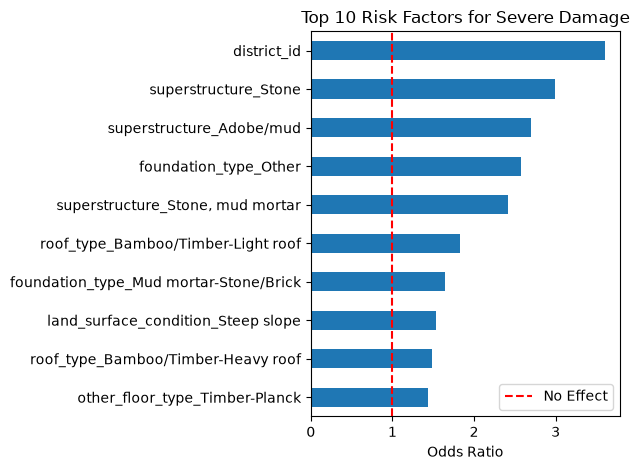

In [82]:
feature_names=model.named_steps["encoder"].get_feature_names_out()
cofficient=model.named_steps["classifier"].coef_[0]
odds_ratio=pd.Series(np.exp(cofficient),index=feature_names).sort_values()
odds_ratio

print("Top 10 features INCREASING odds of severe damage:")
print(odds_ratio.tail(10))

fig,ax=plt.subplots()
odds_ratio.tail(10).plot(kind="barh",ax=ax)
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Risk Factors for Severe Damage')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect')
ax.legend()
plt.tight_layout()
plt.show()